In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import fmatoolbox as fma
import isautilities as isau
import xarray as xr

import pathlib
froot = pathlib.Path().cwd().parent.parent.parent / 'Results'
fig_root = froot / 'Figures' / 'ISAHpcPfc'
fig_root_poster = fig_root / 'PosterFigures'
fig_root_supp = fig_root / 'Supp'
fres = froot / 'Data' / 'characterizeRegions.pkl'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
regs = ['hpc','nr','pfc']
results = {}
do_save = False

unit firing rates

In [2]:
def _unitFR(session, regs=None, when='sleep.*#0'):

    # load data
    R = fma.regions.regions(session, epochs=when, states=('sws','rem'), events='InfraSlowRhythm/infraslowaval')
    regs = R.ids if regs is None else np.asarray(regs)[np.isin(regs,R.ids)]
    spikes = R.spikes()
    unit_reg = np.full(len(R.units()), 'none')
    for r in regs:
        unit_reg[R.units(r)] = r

    conditions = {'isa': R.eventIntervals('slownr'), 'nisa': R.eventIntervals([['sws','/slownr']]),
                  'nrem': R.eventIntervals('sws'), 'rem': R.eventIntervals('rem'), 'wake':  R.eventIntervals('other')}

    fr = []
    for condition in conditions.values():
        fr.append( np.bincount(fma.intervals.restrict(spikes, condition)[:,1].astype(int)) / np.diff(condition).sum() )

    fr = xr.DataArray(fr, dims=['cond','reg'], coords={'cond': list(conditions.keys()), 'reg': unit_reg, 'rat': int(R.rat)})

    return fr

In [3]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][18]
print(session)
fr = _unitFR(session, regs=regs)

/mnt/hubel-data-140/karadoc/Rat004_20240305/Rat004_20240305.xml


In [3]:
_fr = fma.data.runBatch(batch_file, _unitFR, kwargs={'regs': regs}, parallel=True)
fr = {r: xr.concat([d.sel(reg=r) for d in _fr if d is not None if r in d.reg.values], dim='reg', join='outer', coords='all') for r in regs}
results['fr'] = fr


Starting Batch, 2026-11-09 11:44:16.464525 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230819/Rat002_20230819.xml (38)
setting an array element with a sequence

region cross-correlograms

In [2]:
def _regionCCG(session, regs=None, when='sleep.*#0', bin=0.05, limits=(-0.5,0.5)):

    # load data
    R = fma.regions.regions(session, epochs=when, states=('sws','rem'), events='InfraSlowRhythm/infraslowaval')
    regs = R.ids if regs is None else np.asarray(regs)[np.isin(regs,R.ids)]
    n_units = np.array([len(R.units(r)) for r in regs])
    events = isau.loadHpcPfcEvents(session)

    spikes = []
    for i, r in enumerate(regs):
        s = R.spikes(r)
        s[:,1] = i
        spikes.append(s)
    spikes = np.concatenate(spikes)

    conditions = {'isa': R.eventIntervals('slownr'), 'nisa': R.eventIntervals([['sws','/slownr']]),
                  'nrem': R.eventIntervals('sws'), 'rem': R.eventIntervals('rem'), 'wake':  R.eventIntervals('other')}
    # lim_oscill = [[-1,1],[-1,1],[-3,3]]
    # for i, e in enumerate(events):
    #     conditions[e] = events[e][:,None] + lim_oscill[i]

    ccg = []
    for condition in conditions.values():
        s = fma.intervals.restrict(spikes, condition)
        c, t = fma.analysis.CCG(s, bin, limits)
        c /= n_units[:,None,None] # convert to Hz / unit
        ccg.append(c)

    ccg = xr.DataArray(ccg,dims=['cond','reg0','reg1','t'],coords={'cond': list(conditions.keys()), 'reg0': regs, 'reg1': regs, 't': t, 'rat': int(R.rat)})

    return ccg

In [ ]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][18]
print(session)
ccg = _regionCCG(session,regs=regs,bin=0.005,limits=(-0.1,0.1))

In [ ]:
n_regs = len(regs)
conds = ['isa','nisa']
#conds = ccg.cond.values[2:]
#conds = ['isa','ripples']
fig, ax = fma.plotting.figure(n=(n_regs,n_regs),size=(20,16))
for cond in conds:
    for i, r0 in enumerate(regs):
        for j, r1 in enumerate(regs):
            c = ccg.sel(cond=cond).sel(reg0=r0,reg1=r1)
            c -= c.mean(dim='t')
            ax[i,j].axvline(0,color='gray',ls='--')
            ax[i,j].plot(ccg.t,c,label=cond)
            ax[i,j].set(title=f'{r0}-{r1}')
ax[0,0].legend();

run batch

In [3]:
ccg = fma.data.runBatch(batch_file, _regionCCG, kwargs={'regs': regs, 'bin': 0.01, 'limits': (-0.6,0.6)}, parallel=True)
ccg_cat = xr.concat([d for d in ccg if d is not None], dim='rat', join='outer', coords='all') # (event, time, region)
results['ccg_10ms'] = ccg_cat


Starting Batch, 2026-11-09 14:13:24.033719 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
zero-size array to reduction operation maximum which has no identity
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230819/Rat002_20230819.xml (38)
zero-size array to reduction operation maximum which has no identity
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002

In [6]:
ccg = fma.data.runBatch(batch_file, _regionCCG, kwargs={'regs': regs, 'bin': 0.004, 'limits': (-0.1,0.1)}, parallel=True)
ccg_cat = xr.concat([d for d in ccg if d is not None], dim='rat', join='outer', coords='all') # (event, time, region)
results['ccg_5ms'] = ccg_cat


Starting Batch, 2026-11-09 11:45:04.414017 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
zero-size array to reduction operation maximum which has no identity
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230819/Rat002_20230819.xml (38)
zero-size array to reduction operation maximum which has no identity
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002

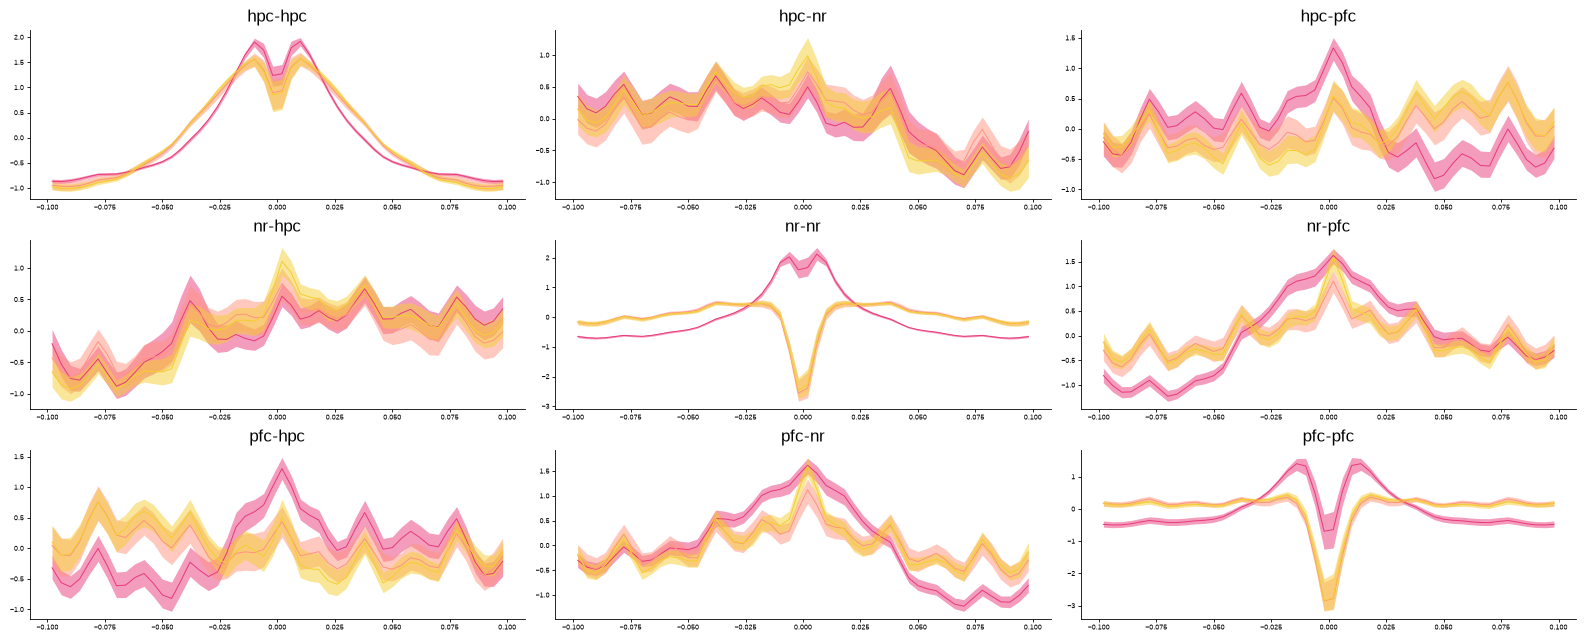

In [23]:
conditions = ('nrem','rem','wake') #['isa','nisa']
n_regs = len(regs)
fig, ax = fma.plotting.figure(n=(n_regs,n_regs), size=(40,16))
for k, cond in enumerate(conditions):
    for i, r0 in enumerate(regs):
        for j, r1 in enumerate(regs):
            ax[i,j].set(title=f'{r0}-{r1}')
            c = ccg_cat.sel(cond=cond).sel(reg0=r0,reg1=r1).values
            fma.plotting.semPlot(ccg_cat.t, c, zscore=2, smooth=1, ax=ax[i,j], color=isau.paperColors(cond))

In [4]:
isau.update_results(results, fres)